# 🌧️ Wesi: Sri Lanka Rainfall Ensemble Lab
### Predicting tomorrow's rainfall in Colombo, Kandy and Galle with Bagging, Boosting, Stacking and an RF + ARIMA hybrid

**Module:** Machine Learning (Semester 7), University of Moratuwa · **Hands-on project:** Ensemble Learning Dashboard · **Author:** Sineth

---

## 🤖 GenAI Usage Declaration
As required by the module's Generative AI policy, I explicitly declare that:

- **Claude (Anthropic)** was used as a coding assistant to write and scaffold the code in this notebook (data download, cleaning, feature engineering, model training, evaluation and SHAP analysis), the Streamlit dashboard code and UI, and the README.
- **Gemini (Google)** was used to brainstorm the overall project plan.
- All AI-assisted code was **executed, checked and reviewed by me**. The dataset is **real** (downloaded from the Open-Meteo API) and was **not** generated by AI. Every number in this notebook comes from actually running the cells.

## 0. Problem statement (Sri Lankan context)
Sri Lanka's wet zone is driven by two monsoons, the **South-West (Yala, May–Sep)** and the **North-East (Maha, Dec–Feb)**, plus stormy **inter-monsoon** periods (Mar–Apr, Oct–Nov). A single heavy-rain day floods Colombo's suburbs, raises landslide risk around Kandy and stops fishing boats in Galle.

**Goal:** predict `rain_tomorrow_mm`, the next-day rainfall (mm), for each city using today's weather and recent history, and compare **Bagging, Boosting, Stacking and Hybrid** ensembles, explaining **why** they perform differently.

## 1. Data source and reproducibility

| Item | Value |
|---|---|
| Source | [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) |
| Underlying data | **ECMWF ERA5 / ERA5-Land reanalysis** (Copernicus Climate Change Service) |
| Cities | Colombo (6.9271, 79.8612), Kandy (7.2906, 80.6337), Galle (6.0535, 80.2210) |
| Period | 2015-01-01 to 2025-12-31, daily |
| Re-download | `python scripts/fetch_data.py` (no API key) |

**Exact API URL (Colombo; Kandy and Galle only change `latitude`/`longitude`):**
```
https://archive-api.open-meteo.com/v1/archive?latitude=6.9271&longitude=79.8612&start_date=2015-01-01&end_date=2025-12-31&daily=temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration&timezone=Asia%2FColombo
```

**What is ERA5 reanalysis?** ECMWF combines millions of **real observations** (weather stations, radiosondes, aircraft, ships, buoys, satellites) with a physics-based weather model through *data assimilation*, producing a consistent, gap-free record on a ~9–31 km grid. It is observation-based and fully reproducible, **not synthetic**. Limitation: it is a grid-cell average, so it smooths extreme cloudbursts and over-counts light-drizzle days compared with a single rain gauge.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path

DATA_PATH = Path("data/sl_weather_2015_2025.csv")
MODELS_DIR = Path("models"); MODELS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

df_raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print("Shape:", df_raw.shape)
print("Date range:", df_raw["date"].min().date(), "to", df_raw["date"].max().date())
print("Rows per city:", df_raw["city"].value_counts().to_dict())
df_raw.head()

Shape: (12054, 22)
Date range: 2015-01-01 to 2025-12-31
Rows per city: {'Colombo': 4018, 'Kandy': 4018, 'Galle': 4018}


,date,city,climate_zone,latitude,longitude,elevation_m,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,...,precipitation_hours,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration
0,2015-01-01,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,28.4,23.2,25.8,31.0,...,7.0,88,23.6,1009.8,39,11.4,27.4,210,18.30,3.51
1,2015-01-02,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,28.8,22.9,25.5,29.9,...,0.0,82,22.1,1011.8,28,9.6,22.0,282,19.63,3.95
2,2015-01-03,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,29.9,20.9,25.6,30.2,...,0.0,81,21.9,1012.3,58,9.9,20.2,300,22.94,4.59
3,2015-01-04,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,29.8,23.2,26.1,30.9,...,0.0,82,22.6,1011.8,37,8.8,20.9,331,18.36,3.78
4,2015-01-05,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,29.6,23.0,26.4,31.6,...,2.0,83,23.1,1011.0,32,7.9,19.4,6,19.99,4.06


In [2]:
# Data types and missing values
info = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum(), "n_unique": df_raw.nunique()})
info

,dtype,missing,n_unique
date,datetime64[ns],0,4018
city,object,0,3
climate_zone,object,0,3
latitude,float64,0,3
longitude,float64,0,3
elevation_m,float64,0,3
temperature_2m_max,float64,0,134
temperature_2m_min,float64,0,126
temperature_2m_mean,float64,0,96
apparent_temperature_mean,float64,0,143


## 2. Data cleaning
Every decision below is documented with the reason. Principle: **remove only what is redundant or physically impossible; keep real extremes**, because extreme rain days are exactly the floods we care about.

In [3]:
df = df_raw.sort_values(["city", "date"]).reset_index(drop=True).copy()
report = {}

# 2.1 Duplicates: one row per (city, date) is expected
report["duplicate (city, date) rows"] = int(df.duplicated(["city", "date"]).sum())

# 2.2 Continuity: every city must have every calendar day (needed for lag features and ARIMA)
full_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
report["missing calendar days"] = int(sum(len(full_days.difference(g["date"])) for _, g in df.groupby("city")))

# 2.3 Redundant column: in tropical Sri Lanka there is no snow, so rain_sum should equal precipitation_sum
report["rows where rain_sum != precipitation_sum"] = int((~np.isclose(df["rain_sum"], df["precipitation_sum"])).sum())

# 2.4 Physical sanity checks (impossible values would indicate corruption)
checks = {
    "precipitation < 0": (df["precipitation_sum"] < 0),
    "Tmin > Tmax": (df["temperature_2m_min"] > df["temperature_2m_max"]),
    "humidity outside 0-100 %": ~df["relative_humidity_2m_mean"].between(0, 100),
    "cloud cover outside 0-100 %": ~df["cloud_cover_mean"].between(0, 100),
    "MSL pressure outside 950-1050 hPa": ~df["pressure_msl_mean"].between(950, 1050),
    "precipitation_hours outside 0-24": ~df["precipitation_hours"].between(0, 24),
    "dew point > air temperature + 0.5": (df["dew_point_2m_mean"] > df["temperature_2m_mean"] + 0.5),
}
for name, mask in checks.items():
    report[name] = int(mask.sum())

pd.Series(report, name="count").to_frame()

,count
"duplicate (city, date) rows",0
missing calendar days,0
rows where rain_sum != precipitation_sum,0
precipitation < 0,0
Tmin > Tmax,0
humidity outside 0-100 %,0
cloud cover outside 0-100 %,0
MSL pressure outside 950-1050 hPa,0
precipitation_hours outside 0-24,0
dew point > air temperature + 0.5,0


In [4]:
# Apply the cleaning decisions
df = df.drop(columns=["rain_sum",            # identical to precipitation_sum (no snow in Sri Lanka)
                      "latitude", "longitude"])  # constant per city, already captured by `city`
df = df.rename(columns={"precipitation_sum": "rain_mm"})

# Extreme rainfall: inspect, but DO NOT delete. These are real monsoon / cyclone events.
top_days = df.nlargest(8, "rain_mm")[["date", "city", "rain_mm", "precipitation_hours", "pressure_msl_mean"]]
print("Wettest days in the record (kept, they are real events):")
top_days

Wettest days in the record (kept, they are real events):


,date,city,rain_mm,precipitation_hours,pressure_msl_mean
500,2016-05-15,Colombo,231.4,24.0,1007.0
3984,2025-11-28,Colombo,217.5,23.0,1007.6
6161,2020-11-13,Galle,200.0,20.0,1009.4
8536,2016-05-15,Kandy,172.5,24.0,1008.8
12019,2025-11-27,Kandy,164.9,24.0,1006.7
4315,2015-10-25,Galle,160.1,24.0,1010.8
5771,2019-10-20,Galle,149.4,24.0,1010.2
12020,2025-11-28,Kandy,138.6,24.0,1006.7


**Cleaning decisions and reasons**

| Decision | Reason |
|---|---|
| Keep all 12,054 rows | No duplicates, no missing days, no missing values, no physically impossible values (table above). |
| Drop `rain_sum` | It is identical to `precipitation_sum`. Sri Lanka has no snowfall, so keeping both would just duplicate information. |
| Drop `latitude`, `longitude` | Constant within each city, so they add nothing beyond the `city` column. |
| **Keep** extreme rainfall days (up to 231 mm) | They are real events (monsoon bursts, deep depressions). Deleting them would teach the model that floods never happen. Instead we handle the skew with a **log1p transform** of the target during modeling. |
| Rename `precipitation_sum` to `rain_mm` | Readability. |

**ERA5 caveat:** reanalysis spreads rain over a ~9–31 km grid cell, so it records small amounts of rain (drizzle) on many days that a single gauge would call dry. That is why only 16–37 % of days are below 1 mm. We keep this in mind when interpreting "rain / no-rain" results.

## 3. Feature engineering (Sri Lankan domain knowledge)
All features use information available **by the end of day *t*** to predict rain on day *t + 1*. Lags and rolling windows are computed **per city**, so Colombo's history never leaks into Kandy's rows by accident (the cross-city features below are deliberate and use the same day only).

| Group | Features | Why it should help |
|---|---|---|
| Persistence | `rain_lag1..3`, `rain_roll3/7/14/30` (mean), `wet_streak`, `dry_streak` | Monsoon spells last for days, so recent rain is the strongest single signal. |
| Atmosphere today | humidity, dew point, dew-point depression, cloud cover, radiation, ET0, pressure | Moist, cloudy, low-pressure air is primed for convection. |
| Tendencies | `pressure_change_1d`, `humidity_change_1d`, `temp_range` | Falling pressure signals an approaching low / depression. |
| Wind | `wind_u`, `wind_v` (from speed + direction), gusts | South-westerly flow brings Yala rain to the west and south coasts; north-easterly brings Maha rain. |
| Season | `monsoon_season` (SW, NE, First / Second inter-monsoon), `doy_sin`, `doy_cos`, `month` | Sri Lanka's rain is strongly seasonal. |
| Spatial | `rain_today_colombo/kandy/galle` | Weather systems move across the island; rain in one city today can foreshadow another tomorrow. |
| Location | `city` (one-hot), `elevation_m` | Kandy sits at ~500 m in the central hills, with a different rain regime from the coast. |

In [5]:
def monsoon_season(month):
    if month in (5, 6, 7, 8, 9):
        return "SW monsoon (Yala)"
    if month in (12, 1, 2):
        return "NE monsoon (Maha)"
    if month in (3, 4):
        return "First inter-monsoon"
    return "Second inter-monsoon"   # Oct, Nov


def streak(is_true):
    # length of the current run of True values, reset on False
    run = is_true.astype(int)
    return run.groupby((run != run.shift()).cumsum()).cumsum() * run


def build_features(d):
    d = d.sort_values(["city", "date"]).copy()
    g = d.groupby("city", group_keys=False)

    # Persistence
    for k in (1, 2, 3):
        d[f"rain_lag{k}"] = g["rain_mm"].shift(k)
    for w in (3, 7, 14, 30):
        d[f"rain_roll{w}"] = g["rain_mm"].transform(lambda s: s.rolling(w, min_periods=w).mean())
    d["wet_streak"] = g["rain_mm"].transform(lambda s: streak(s >= 1))
    d["dry_streak"] = g["rain_mm"].transform(lambda s: streak(s < 1))
    d["precip_hours_lag1"] = g["precipitation_hours"].shift(1)

    # Atmosphere and tendencies
    d["temp_range"] = d["temperature_2m_max"] - d["temperature_2m_min"]
    d["dewpoint_depression"] = d["temperature_2m_mean"] - d["dew_point_2m_mean"]
    d["pressure_change_1d"] = g["pressure_msl_mean"].diff(1)
    d["humidity_change_1d"] = g["relative_humidity_2m_mean"].diff(1)

    # Wind vector (meteorological direction = where the wind comes FROM)
    rad = np.deg2rad(d["wind_direction_10m_dominant"])
    d["wind_u"] = -d["wind_speed_10m_max"] * np.sin(rad)
    d["wind_v"] = -d["wind_speed_10m_max"] * np.cos(rad)

    # Season
    d["month"] = d["date"].dt.month
    doy = d["date"].dt.dayofyear
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    d["monsoon_season"] = d["month"].map(monsoon_season)

    # Spatial: every city's rain today, joined on date
    wide = d.pivot(index="date", columns="city", values="rain_mm")
    wide.columns = [f"rain_today_{c.lower()}" for c in wide.columns]
    d = d.merge(wide, left_on="date", right_index=True, how="left")

    # Targets: tomorrow's rain in the same city
    d["rain_tomorrow_mm"] = d.groupby("city")["rain_mm"].shift(-1)
    d["rain_tomorrow_event"] = (d["rain_tomorrow_mm"] >= 10).astype(int)   # >= 10 mm = "rainy day that matters"
    return d


feat = build_features(df)
before = len(feat)
feat = feat.dropna().reset_index(drop=True)   # first 30 days (rolling window) and last day (no tomorrow) per city
print(f"Rows: {before} -> {len(feat)} after dropping warm-up/last-day rows ({before - len(feat)} removed)")

Rows: 12054 -> 11964 after dropping warm-up/last-day rows (90 removed)


In [6]:
TARGET = "rain_tomorrow_mm"
CAT_FEATURES = ["city", "monsoon_season"]
NUM_FEATURES = [
    "rain_mm", "rain_lag1", "rain_lag2", "rain_lag3",
    "rain_roll3", "rain_roll7", "rain_roll14", "rain_roll30",
    "wet_streak", "dry_streak", "precipitation_hours", "precip_hours_lag1",
    "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean", "temp_range",
    "relative_humidity_2m_mean", "humidity_change_1d", "dew_point_2m_mean", "dewpoint_depression",
    "pressure_msl_mean", "pressure_change_1d", "cloud_cover_mean",
    "wind_speed_10m_max", "wind_gusts_10m_max", "wind_u", "wind_v",
    "shortwave_radiation_sum", "et0_fao_evapotranspiration",
    "month", "doy_sin", "doy_cos", "elevation_m",
    "rain_today_colombo", "rain_today_kandy", "rain_today_galle",
]
FEATURES = NUM_FEATURES + CAT_FEATURES

# Time-based split: no shuffling, the model never sees the future
feat["split"] = np.select(
    [feat["date"] < "2023-01-01", feat["date"] < "2024-01-01"],
    ["train", "valid"], default="test")

summary = feat.groupby("split").agg(rows=("date", "size"), start=("date", "min"), end=("date", "max"),
                                    mean_target_mm=(TARGET, "mean"), heavy_rain_share=("rain_tomorrow_event", "mean"))
print(f"{len(FEATURES)} features ({len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical)")
summary.loc[["train", "valid", "test"]].round(3)

39 features (37 numeric + 2 categorical)


,rows,start,end,mean_target_mm,heavy_rain_share
split,,,,,
train,8679,2015-01-30,2022-12-31,6.705,0.214
valid,1095,2023-01-01,2023-12-31,8.088,0.275
test,2190,2024-01-01,2025-12-30,7.588,0.248


In [7]:
# Save the engineered dataset for Stage 4 and the dashboard
feat.to_csv("data/sl_weather_features.csv", index=False)
print("Saved data/sl_weather_features.csv", feat.shape)

Saved data/sl_weather_features.csv (11964, 45)


## 3b. Exploratory data analysis

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
CITY_COLORS = {"Colombo": "#1f77b4", "Kandy": "#2ca02c", "Galle": "#ff7f0e"}
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

### EDA 1: The target is extremely skewed

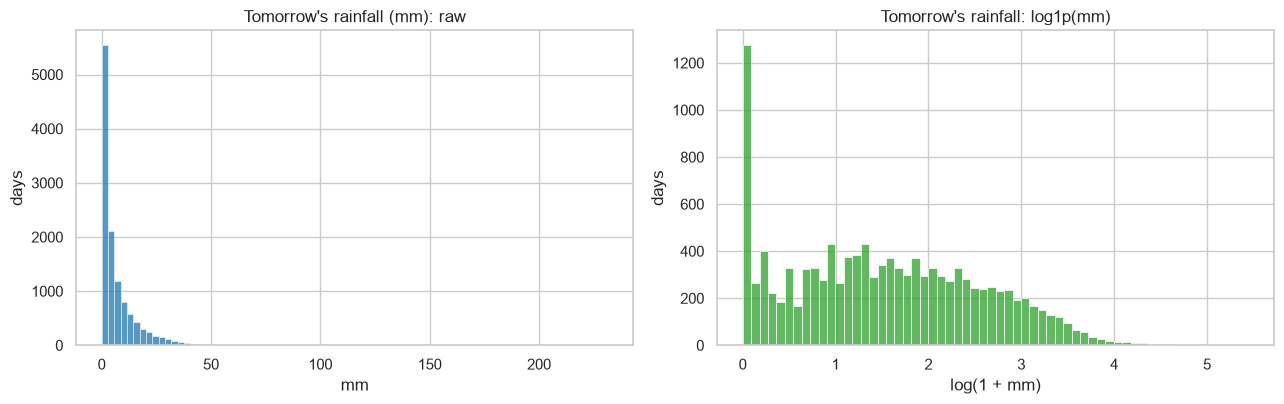

Quantiles (mm): {0.5: 3.3, 0.75: 9.0, 0.9: 18.4, 0.95: 25.7, 0.99: 43.1} | skewness raw: 5.65 | skewness log1p: 0.27


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(feat[TARGET], bins=80, ax=axes[0], color="#1f77b4")
axes[0].set(title="Tomorrow's rainfall (mm): raw", xlabel="mm", ylabel="days")
sns.histplot(np.log1p(feat[TARGET]), bins=60, ax=axes[1], color="#2ca02c")
axes[1].set(title="Tomorrow's rainfall: log1p(mm)", xlabel="log(1 + mm)", ylabel="days")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_target_distribution.png", dpi=130); plt.show()

q = feat[TARGET].quantile([.5, .75, .9, .95, .99]).round(1)
print("Quantiles (mm):", q.to_dict(), "| skewness raw:", round(feat[TARGET].skew(), 2),
      "| skewness log1p:", round(np.log1p(feat[TARGET]).skew(), 2))

**Takeaway:** rainfall is extremely right-skewed (skewness 5.65): the median day gets 3.3 mm but the wettest 1 % of days get more than 43 mm. After `log1p` the skewness drops to 0.27, almost symmetric. **Decision:** models are trained on `log1p(rain)` and predictions are converted back to mm with `expm1`. This stops a handful of flood days from dominating the squared-error loss.

### EDA 2: Monsoon climatology, the two-peak rainfall year

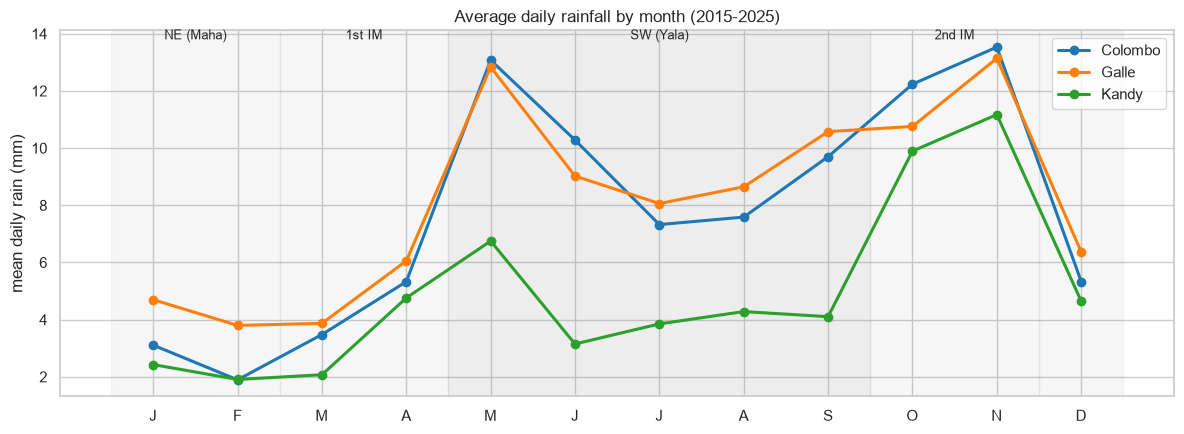

month,1,2,3,4,5,6,7,8,9,10,11,12
city,,,,,,,,,,,,
Colombo,3.1,1.9,3.5,5.3,13.1,10.3,7.3,7.6,9.7,12.2,13.5,5.3
Galle,4.7,3.8,3.9,6.1,12.8,9.0,8.1,8.6,10.6,10.8,13.1,6.4
Kandy,2.4,1.9,2.1,4.8,6.7,3.1,3.8,4.3,4.1,9.9,11.2,4.6


In [10]:
clim = df.assign(month=df["date"].dt.month).groupby(["city", "month"])["rain_mm"].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 4.5))
for s, (a, b) in {"NE (Maha)": (0.5, 2.5), "1st IM": (2.5, 4.5), "SW (Yala)": (4.5, 9.5), "2nd IM": (9.5, 11.5)}.items():
    ax.axvspan(a, b, alpha=0.07 if s != "SW (Yala)" else 0.14, color="grey"); ax.text((a + b) / 2, clim["rain_mm"].max() * 1.02, s, ha="center", fontsize=9)
for city, g in clim.groupby("city"):
    ax.plot(g["month"], g["rain_mm"], marker="o", lw=2.2, label=city, color=CITY_COLORS[city])
ax.set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"), ylabel="mean daily rain (mm)",
       title="Average daily rainfall by month (2015-2025)")
ax.axvspan(11.5, 12.5, alpha=0.07, color="grey")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "eda_monsoon_climatology.png", dpi=130); plt.show()
clim.pivot(index="month", columns="city", values="rain_mm").round(1).T

**Takeaway:** the data reproduces Sri Lanka's textbook **two-peak rainfall year**. Colombo and Galle peak in **May** (SW monsoon onset, ~13 mm/day) and again in **October–November** (second inter-monsoon, 12–13.5 mm/day), while January–March are the driest months. Kandy, in the central hills, is in the rain shadow of the SW monsoon (only 3–4 mm/day in June–September) and gets its main rain in October–November. **The same weather can mean different things in different cities**, which is why `city`, `monsoon_season` and the seasonal terms are features, and why tree ensembles (which can learn interactions such as *season × city*) should beat linear models.

### EDA 3: Rain persistence (does today predict tomorrow?)

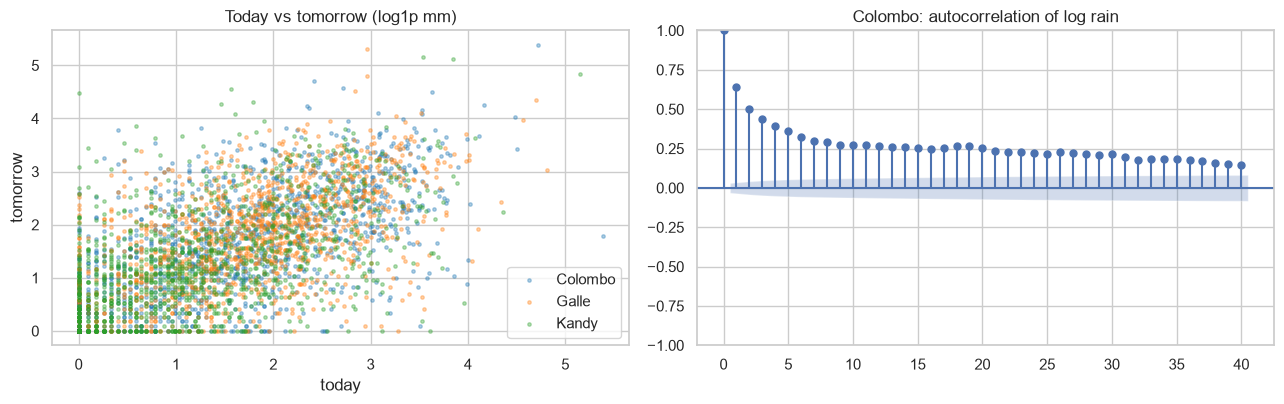

Lag-1 correlation of log rain, by city: {'Colombo': 0.639, 'Galle': 0.586, 'Kandy': 0.586}


In [11]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sample = feat.sample(4000, random_state=RANDOM_STATE)
for city, g in sample.groupby("city"):
    axes[0].scatter(np.log1p(g["rain_mm"]), np.log1p(g[TARGET]), s=6, alpha=0.35, label=city, color=CITY_COLORS[city])
axes[0].set(title="Today vs tomorrow (log1p mm)", xlabel="today", ylabel="tomorrow"); axes[0].legend()
plot_acf(np.log1p(df.loc[df.city == "Colombo", "rain_mm"]), lags=40, ax=axes[1], title="Colombo: autocorrelation of log rain")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_persistence.png", dpi=130); plt.show()

pers = feat.groupby("city").apply(lambda g: np.corrcoef(np.log1p(g["rain_mm"]), np.log1p(g[TARGET]))[0, 1])
print("Lag-1 correlation of log rain, by city:", pers.round(3).to_dict())

**Takeaway:** today's rain correlates with tomorrow's at **r ≈ 0.59–0.64** (log scale), and the autocorrelation stays positive for weeks. Wet spells and dry spells persist. This is the signal ARIMA can model, and why a **persistence baseline** ("tomorrow = today") is the bar every ensemble must beat. The scatter is also very wide, so persistence alone leaves a lot unexplained: the remaining variance must come from the atmosphere (humidity, pressure, wind) and from non-linear interactions.

### EDA 4: Which features move with tomorrow's rain?

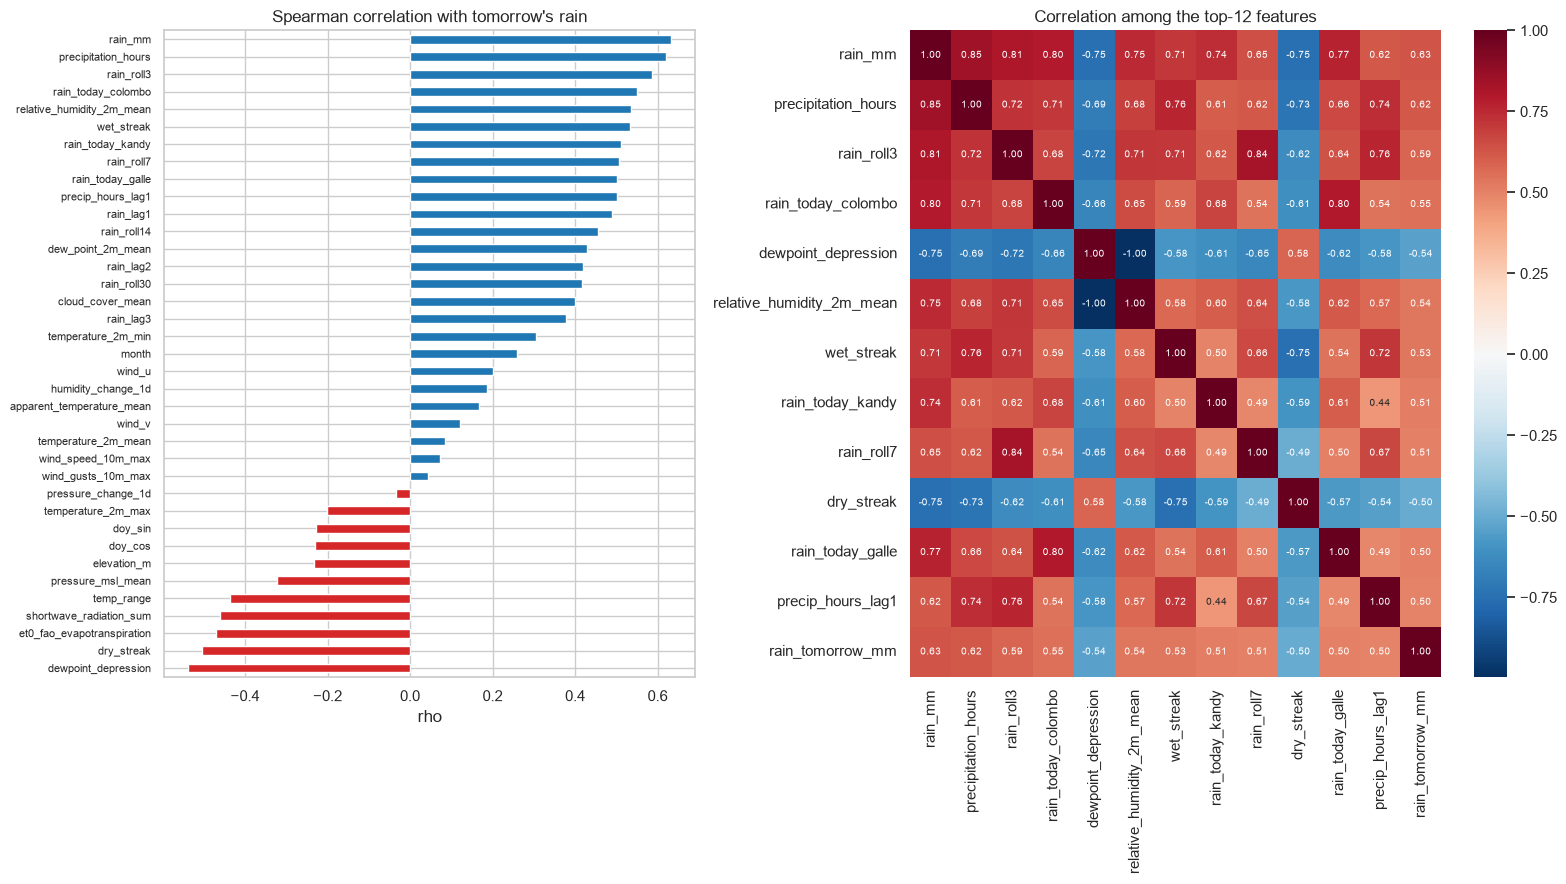

rain_mm                      0.633
precipitation_hours          0.620
rain_roll3                   0.586
rain_today_colombo           0.550
dewpoint_depression          0.537
relative_humidity_2m_mean    0.536
wet_streak                   0.532
rain_today_kandy             0.512
rain_roll7                   0.507
dry_streak                   0.504
Name: rain_tomorrow_mm, dtype: float64

In [12]:
corr = feat[NUM_FEATURES + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [1, 1.25]})
corr.plot.barh(ax=axes[0], color=np.where(corr > 0, "#1f77b4", "#d62728"))
axes[0].set(title="Spearman correlation with tomorrow's rain", xlabel="rho"); axes[0].tick_params(axis="y", labelsize=8)
top = corr.abs().sort_values(ascending=False).index[:12].tolist() + [TARGET]
sns.heatmap(feat[top].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Correlation among the top-12 features")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_correlations.png", dpi=130); plt.show()
corr.abs().sort_values(ascending=False).head(10).round(3)

**Takeaway:** the strongest drivers are the **persistence** features (today's rain, precipitation hours, 3-day rolling mean, wet/dry streaks), the **moisture** features (humidity, dew-point depression) and the **spatial** features (today's rain in Colombo, Kandy and Galle). Rain moves across the island, so a neighbour's rain is informative. Sunshine (radiation, ET0) and a large diurnal temperature range point to *dry* tomorrows.

**Multicollinearity warning:** humidity and dew-point depression are almost perfectly correlated (ρ = −1.00), and `rain_mm`, `rain_roll3` and `precipitation_hours` overlap heavily (0.72–0.85). Tree ensembles cope with this, but it **splits feature importance between correlated twins**. We must remember this when reading SHAP plots in Section 6.

### EDA 5: Rain by monsoon season and city

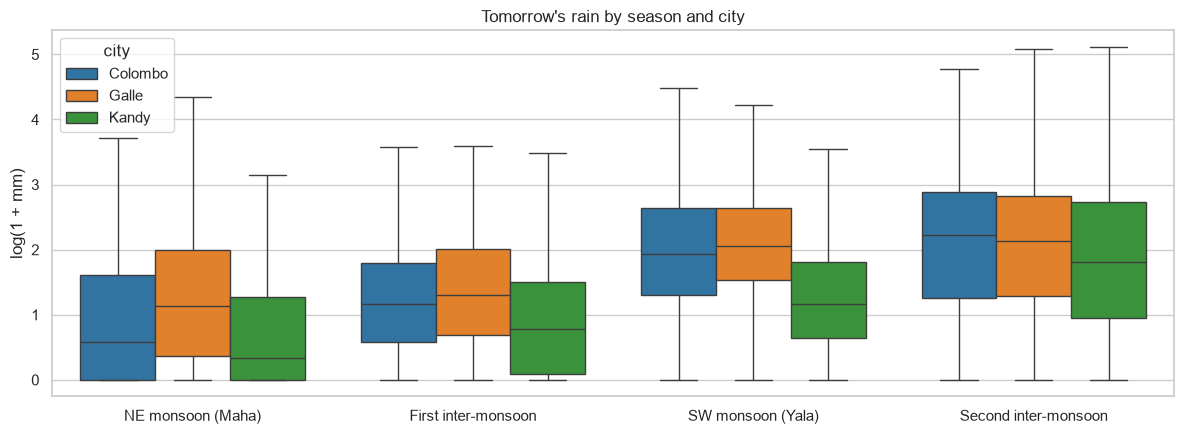

city,Colombo,Galle,Kandy
monsoon_season,,,
NE monsoon (Maha),0.105,0.161,0.091
First inter-monsoon,0.127,0.140,0.095
SW monsoon (Yala),0.334,0.340,0.114
Second inter-monsoon,0.438,0.401,0.340


In [13]:
order = ["NE monsoon (Maha)", "First inter-monsoon", "SW monsoon (Yala)", "Second inter-monsoon"]
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=feat, x="monsoon_season", y=np.log1p(feat[TARGET]), hue="city", order=order,
            palette=CITY_COLORS, showfliers=False, ax=ax)
ax.set(title="Tomorrow's rain by season and city", xlabel="", ylabel="log(1 + mm)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_season_city.png", dpi=130); plt.show()
feat.pivot_table(index="monsoon_season", columns="city", values="rain_tomorrow_event", aggfunc="mean").loc[order].round(3)

**Takeaway:** the probability of a **heavy-rain tomorrow (≥ 10 mm)** depends strongly on both season and city. On the coast it is highest in the second inter-monsoon (Colombo 44 %, Galle 40 %) and the SW monsoon (33–34 %). Kandy is only 11 % in the SW monsoon but 34 % in Oct–Nov. In the NE monsoon all three wet-zone cities are relatively dry (9–16 %). This **season × city interaction** is exactly what boosting trees capture well.

### EDA 6: Year-to-year totals (is there a trend or an anomaly?)

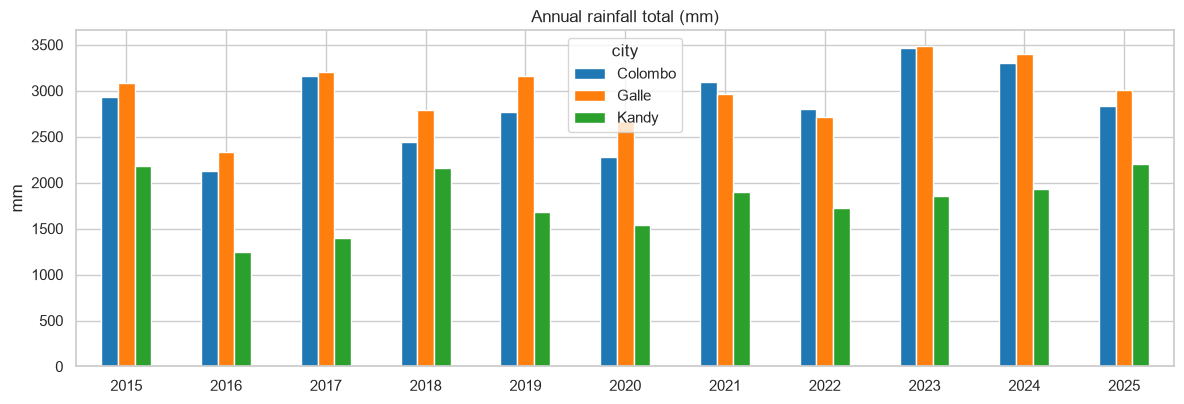

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
city,,,,,,,,,,,
Colombo,2928,2124,3155,2438,2763,2280,3096,2804,3468,3301,2828
Galle,3081,2333,3207,2787,3162,2666,2962,2719,3481,3404,3012
Kandy,2186,1248,1402,2154,1683,1534,1895,1719,1850,1930,2204


In [14]:
annual = df.assign(year=df["date"].dt.year).groupby(["year", "city"])["rain_mm"].sum().unstack()
ax = annual.plot(kind="bar", figsize=(12, 4.2), color=[CITY_COLORS[c] for c in annual.columns])
ax.set(title="Annual rainfall total (mm)", xlabel="", ylabel="mm"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_annual_totals.png", dpi=130); plt.show()
annual.round(0).astype(int).T

**Takeaway:** annual totals swing a lot between years: Colombo ranges from 2,124 mm (2016) to 3,468 mm (2023), with no clean upward or downward trend over 11 years. **2016 is the driest year for all three cities**, matching Sri Lanka's 2016–17 drought, yet 15 May 2016 is also the wettest single day in the record (231 mm in Colombo, from the depression that became **Cyclone Roanu**). The late-November 2025 extremes (217 mm in Colombo, 165 mm in Kandy) line up with **Cyclone Ditwah**. The data captures real, well-known Sri Lankan events, a good sanity check that it is genuine.

The validation year (2023) and test years (2024–2025) are **wetter than the training average** (8.1 and 7.6 mm/day vs 6.7). This is a realistic distribution shift, and it makes the test a fair and slightly harder evaluation.

### Stage 3 summary
- **Cleaned dataset:** 12,054 rows, 0 missing, 0 duplicates, 0 impossible values. One redundant column and two constant columns dropped. Real extremes kept.
- **Modeling table:** 11,964 rows × 39 features (37 numeric + `city`, `monsoon_season`). The 90 removed rows are the 30-day rolling warm-up and the last day per city (no "tomorrow").
- **Split (time-based):** train 2015-01-30 → 2022-12-31 (8,679 rows), validation 2023 (1,095), test 2024-01-01 → 2025-12-30 (2,190).
- **Target:** `rain_tomorrow_mm`, modelled as `log1p`. Secondary label `rain_tomorrow_event` (≥ 10 mm) for the dashboard's rain-alert view.

## 4. Modeling: Bagging, Boosting, Stacking, RF + ARIMA hybrid (Stage 4)

_To be completed in the next stage._

## 5. Model comparison (Stage 4)

_To be completed in the next stage._

## 6. Explainability (SHAP) and why the models behave differently (Stage 4)

_To be completed in the next stage._

## 7. Save models for the dashboard (Stage 4)

_To be completed in the next stage._